24.10. model_24_10: SquareGMM of Simon, feat=70, inflate_full=True, delta=0.005, max_feature_dim=70, max_model_dim=70, prior.gmm.max_num_cluster=70, EPOCHS=50, BATCH_SIZE=6, nlayer=6, nhead=2,

---> BEST MODEL: model_24_10

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import seaborn as sns
import pickle
import torch

In [ ]:
model_1_dir = "../ckpt/(BESTMODEL)dataSGMM.context5000.feat70.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs6.lr0.001.emb256.hdim512.nhead2.nlayer6.ndevice1.numclusters70/seed0/train_val_loss.pickle"
model_1_best_dir = "../ckpt/(BESTMODEL)dataSGMM.context5000.feat70.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs6.lr0.001.emb256.hdim512.nhead2.nlayer6.ndevice1.numclusters70/seed0/best.ckpt"
model_1_best_val_dir = "../ckpt/(BESTMODEL)dataSGMM.context5000.feat70.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs6.lr0.001.emb256.hdim512.nhead2.nlayer6.ndevice1.numclusters70/seed0/best_val.ckpt"
model_1_last_dir = "../ckpt/(BESTMODEL)dataSGMM.context5000.feat70.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs6.lr0.001.emb256.hdim512.nhead2.nlayer6.ndevice1.numclusters70/seed0/last.ckpt"


In [3]:
# load pickel
with open(model_1_dir, "rb") as f:
    data = pickle.load(f)

train_loss = data["train_loss"]
val_loss = data["val_loss"]
train_time = data['train_time']

print("Train loss:", train_loss)
print("Val loss:", val_loss)
print("Train time", train_time)



Train loss: [0.3487332809865475, 0.254312922000885, 0.16556346998736263, 0.12212395676225424, 0.11325715148821473, 0.09660748061165214, 0.09790045452862978, 0.10132623309642076, 0.1105360608510673, 0.10007186629995704, 0.10584048253297806, 0.10951527740806341, 0.1008393995910883, 0.09324102178961038, 0.08626529463380575, 0.07849422319605946, 0.07427767902426421, 0.0877196797169745, 0.0763657769728452, 0.0725594030842185, 0.06615372134558857, 0.06445051426813006, 0.06775196404382587, 0.06176600258779945, 0.058259510684525596, 0.06370669184532017, 0.05425712195876986, 0.05495798341277987, 0.05366903138067573, 0.050688513060100374, 0.04986994471680373, 0.04835462830262258, 0.047474706767126916, 0.04593286014674231, 0.044660563234239815, 0.04200344233971555, 0.04319899855740368, 0.04074979395605624, 0.04045378279639408, 0.039868213497567924, 0.0386560616265051, 0.03831545849867689, 0.0404429675093852, 0.037886799247935414, 0.03702436676062643, 0.035546364923706275, 0.036369837802369145, 0.

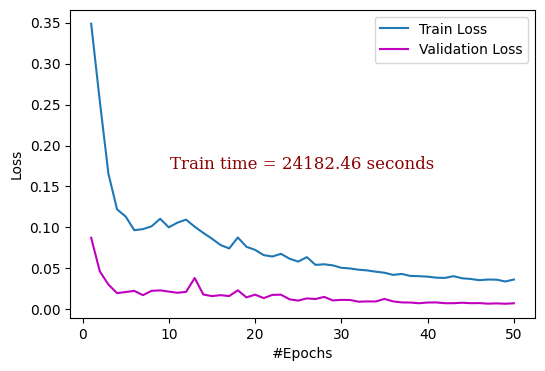

In [5]:
# plot
# plot of model_10
font = {'family': 'serif',
        'color':  'darkred',
        'weight': 'normal',
        'size': 12,
        }

epochs = range(1, len(train_loss) + 1)
plt.figure(figsize=(6, 4))
plt.plot(epochs, train_loss, label="Train Loss")
plt.plot(epochs, val_loss, label="Validation Loss", color='m')
plt.text(
    0.5, 0.5,
    r'Train time = 24182.46 seconds',
    fontdict=font,
    ha='center', va='center',
    transform=plt.gca().transAxes
)

plt.xlabel("#Epochs")
plt.ylabel("Loss")
#plt.title("Training vs Validation Loss")
plt.legend()
#plt.grid(True)

plt.show()

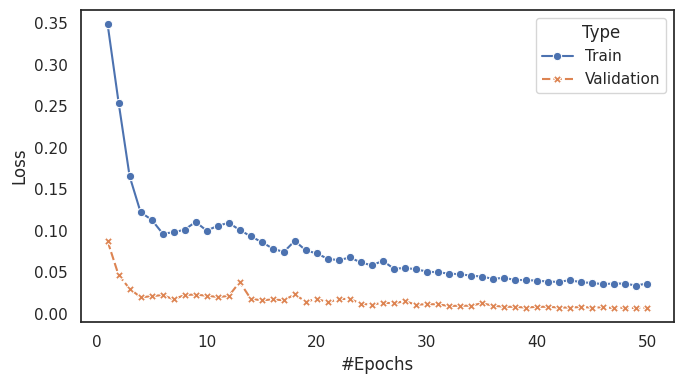

In [23]:
# load data
with open(model_1_dir, "rb") as f:
    data = pickle.load(f)

train_loss = data["train_loss"]
val_loss = data["val_loss"]

epochs = list(range(1, len(train_loss)+1))

# convert to dataframe (seaborn prefers tidy format)
df = pd.DataFrame({
    "#Epochs": epochs + epochs,
    "Loss": train_loss + val_loss,
    "Type": ["Train"]*len(train_loss) + ["Validation"]*len(val_loss)
})

# seaborn style
sns.set_theme(style="white")  # darkgrid

plt.figure(figsize=(7,4))

ax = sns.lineplot(
    data=df,
    x="#Epochs",
    y="Loss",
    hue="Type",
    style="Type",
    markers=True,
    dashes=True
)

# Force integer ticks
#ax.xaxis.set_major_locator(MaxNLocator(len(epochs), integer=True))

#plt.title("Training vs Validation Loss")
plt.tight_layout()

plt.show()